# Support Vector Machine from Scratch
We build a soft-margin linear SVM using only **NumPy**, then use a feature map to see the idea behind the **kernel trick**.

**Labels are −1 and +1.** The model is a hyperplane: $f(x) = w \cdot x + b$, and we predict $\text{sign}(f(x))$.

**What SVM minimizes (soft margin):**
$$J(w, b) = \frac{1}{2}\|w\|^2 + C \sum_i \max\big(0,\; 1 - y_i (w \cdot x_i + b)\big)$$
- $\frac{1}{2}\|w\|^2$ small → **wide margin** ($\text{margin} = 2 / \|w\|$)
- the hinge term → **few points inside the margin or on the wrong side**
- $C$ balances the two

## 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Create the data
Two groups of points with a small overlap. Labels are **−1** and **+1**.

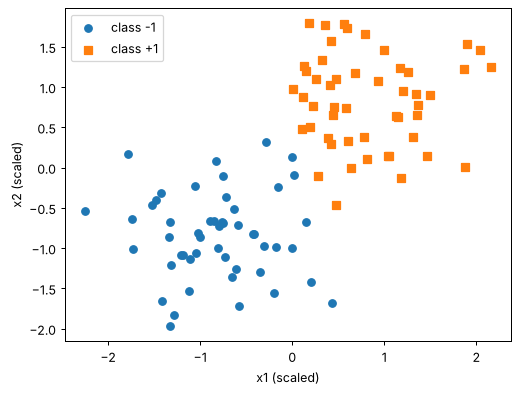

In [2]:
np.random.seed(0)
X = np.vstack([np.random.normal([2, 2], 1.0, size=(50, 2)),
               np.random.normal([5, 5], 1.0, size=(50, 2))])
y = np.array([-1] * 50 + [1] * 50)

# standardize: gradient descent and margins work best on similar scales
mean, std = X.mean(axis=0), X.std(axis=0)
Xs = (X - mean) / std

plt.scatter(Xs[y == -1, 0], Xs[y == -1, 1], label="class -1")
plt.scatter(Xs[y == 1, 0], Xs[y == 1, 1], marker="s", label="class +1")
plt.xlabel("x1 (scaled)")
plt.ylabel("x2 (scaled)")
plt.legend()
plt.show()

## 3. Hyperplane, score and distance
The **score** $w \cdot x + b$ tells the side; dividing by $\|w\|$ gives the real **distance** to the hyperplane.

In [3]:
w_demo, b_demo = np.array([2.0, 1.0]), -4.0
for p in [np.array([1, 1]), np.array([3, 2]), np.array([2, 0])]:
    score = p @ w_demo + b_demo
    side = "+1" if score > 0 else ("-1" if score < 0 else "on the line")
    print(f"point {p}: score = {score:+.1f}, distance = {score / np.linalg.norm(w_demo):+.2f}, side = {side}")

point [1 1]: score = -1.0, distance = -0.45, side = -1
point [3 2]: score = +4.0, distance = +1.79, side = +1
point [2 0]: score = +0.0, distance = +0.00, side = on the line


## 4. Hinge loss
$\max(0, 1 - y \cdot f(x))$ is **0** for points on the correct side and outside the margin, and grows linearly otherwise.

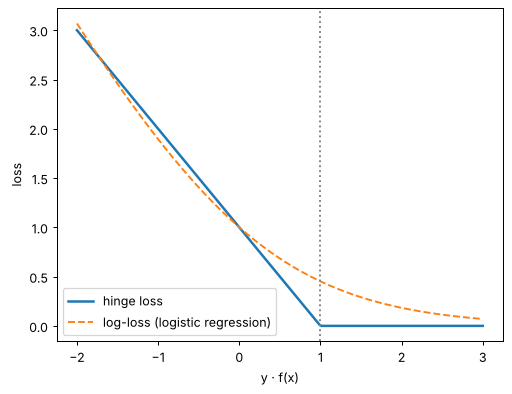

In [4]:
def hinge(y, f):
    return np.maximum(0, 1 - y * f)

yf = np.linspace(-2, 3, 200)
plt.plot(yf, np.maximum(0, 1 - yf), linewidth=2, label="hinge loss")
plt.plot(yf, np.log2(1 + np.exp(-yf)), "--", label="log-loss (logistic regression)")
plt.axvline(1, color="grey", linestyle=":")
plt.xlabel("y · f(x)")
plt.ylabel("loss")
plt.legend()
plt.show()

## 5. Training with (sub)gradient descent
For points that violate the margin ($y_i f(x_i) < 1$) the hinge term has a gradient; for the others it is 0:
$$\frac{\partial J}{\partial w} = w - C \sum_{\text{violators}} y_i x_i \qquad \frac{\partial J}{\partial b} = -C \sum_{\text{violators}} y_i$$

In [5]:
class MyLinearSVM:
    def __init__(self, C=1.0, lr=0.001, epochs=20000):
        self.C, self.lr, self.epochs = C, lr, epochs

    def objective(self, X, y):
        return 0.5 * self.w @ self.w + self.C * hinge(y, X @ self.w + self.b).sum()

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.history = []
        for epoch in range(self.epochs):
            margins = y * (X @ self.w + self.b)
            viol = margins < 1                                   # inside the margin or wrong side
            dw = self.w - self.C * (y[viol, None] * X[viol]).sum(axis=0)
            db = -self.C * y[viol].sum()
            self.w -= self.lr * dw
            self.b -= self.lr * db
            self.history.append(self.objective(X, y))
        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

w = [1.7519 1.2456]   b = -0.095
margin width 2/||w|| = 0.93
training accuracy: 0.99


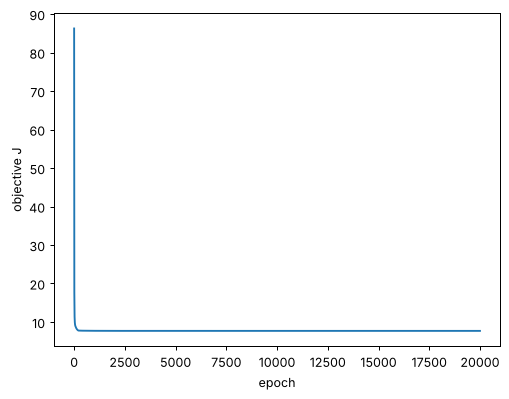

In [6]:
svm = MyLinearSVM(C=1.0).fit(Xs, y)
print("w =", svm.w.round(4), "  b =", round(svm.b, 4))
print("margin width 2/||w|| =", round(2 / np.linalg.norm(svm.w), 3))
print("training accuracy:", np.mean(svm.predict(Xs) == y))

plt.plot(svm.history)
plt.xlabel("epoch")
plt.ylabel("objective J")
plt.show()

## 6. Support vectors
The points on or inside the margin ($y_i f(x_i) \le 1$) are the **support vectors**. Only they decide where the hyperplane goes.

number of support vectors: 10 of 100


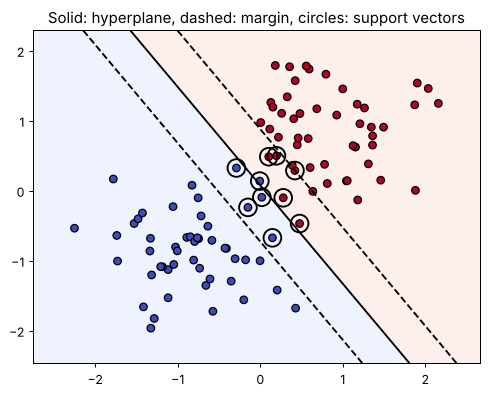

In [7]:
scores = svm.decision_function(Xs)
sv = y * scores <= 1 + 1e-3
print("number of support vectors:", sv.sum(), "of", len(y))

def plot_svm(model, X, y, sv=None, title=""):
    a, b = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                       np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.decision_function(np.c_[a.ravel(), b.ravel()]).reshape(a.shape)
    plt.contourf(a, b, Z > 0, alpha=0.15, cmap="coolwarm")
    plt.contour(a, b, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    if sv is not None:
        plt.scatter(X[sv, 0], X[sv, 1], s=200, facecolors="none", edgecolors="k", linewidths=1.5)
    plt.title(title)
    plt.show()

plot_svm(svm, Xs, y, sv, "Solid: hyperplane, dashed: margin, circles: support vectors")

## 7. The effect of C
Small C → wide margin, many support vectors. Large C → narrow margin, few support vectors.

In [8]:
for C in [0.01, 0.1, 1, 10]:
    m = MyLinearSVM(C=C).fit(Xs, y)
    n_sv = np.sum(y * m.decision_function(Xs) <= 1 + 1e-3)
    print(f"C = {C:<5} margin = {2 / np.linalg.norm(m.w):.2f}  support vectors = {n_sv:3}  "
          f"accuracy = {np.mean(m.predict(Xs) == y):.2f}")

C = 0.01  margin = 3.01  support vectors =  74  accuracy = 0.97
C = 0.1   margin = 1.61  support vectors =  26  accuracy = 0.97
C = 1     margin = 0.93  support vectors =  10  accuracy = 0.99
C = 10    margin = 0.38  support vectors =   5  accuracy = 1.00


## 8. Compare with scikit-learn
`SVC(kernel="linear", C=1)` minimizes exactly the same objective.

In [9]:
from sklearn.svm import SVC

sk = SVC(kernel="linear", C=1.0).fit(Xs, y)
print("our w:     ", svm.w.round(4), " b:", round(svm.b, 3))
print("sklearn w: ", sk.coef_[0].round(4), " b:", round(sk.intercept_[0], 3))
print("sklearn support vectors:", len(sk.support_))
print("same predictions:", np.mean(svm.predict(Xs) == sk.predict(Xs)) * 100, "%")

our w:      [1.7519 1.2456]  b: -0.095
sklearn w:  [1.7519 1.2456]  b: -0.099
sklearn support vectors: 10
same predictions: 100.0 %


The weights match to four decimals. The bias can differ by a few hundredths: when no support vector sits exactly on the margin, several values of $b$ give the same minimum, and each method picks one of them.

# Part 2: Beyond straight lines
## 9. Data that a line cannot separate
A ring around a center: no straight line splits it.

linear SVM accuracy on the rings: 0.675


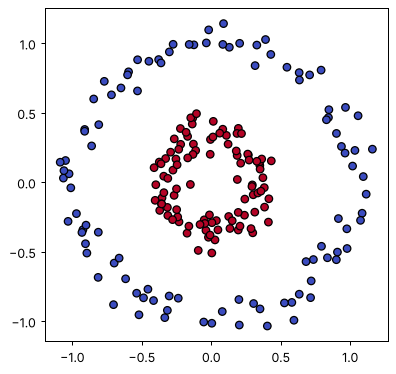

In [10]:
from sklearn.datasets import make_circles

Xc, yc01 = make_circles(200, factor=0.35, noise=0.08, random_state=1)
yc = np.where(yc01 == 1, 1, -1)                 # inner ring = +1, outer = -1

lin = MyLinearSVM(C=1.0).fit(Xc, yc)
print("linear SVM accuracy on the rings:", np.mean(lin.predict(Xc) == yc))
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolors="k")
plt.gca().set_aspect("equal")
plt.show()

## 10. Add a feature: lift the data to 3-D
With $z = x_1^2 + x_2^2$ (squared distance from the center), the inner ring is low and the outer ring is high, so a **flat plane** separates them.

In [11]:
def lift(X):
    return np.c_[X, (X ** 2).sum(axis=1)]           # (x1, x2, x1² + x2²)

Xl = lift(Xc)
svm3d = MyLinearSVM(C=1.0).fit(Xl, yc)
print("linear SVM on lifted data, accuracy:", np.mean(svm3d.predict(Xl) == yc))
print("w =", svm3d.w.round(3), " b =", round(svm3d.b, 3))

linear SVM on lifted data, accuracy: 1.0
w = [ 0.141  0.233 -3.265]  b = 1.682


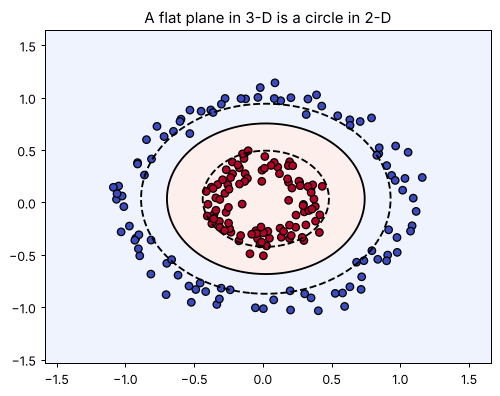

In [12]:
class Lifted:
    # wraps the 3-D model so we can draw its boundary back in 2-D
    def __init__(self, model): self.model = model
    def decision_function(self, X): return self.model.decision_function(lift(X))

plot_svm(Lifted(svm3d), Xc, yc, title="A flat plane in 3-D is a circle in 2-D")

## 11. The kernel trick
Lifting by hand gets expensive with many features. But SVM only needs **dot products** between points, and a **kernel** computes the dot product in the lifted space directly:
$$K(x, z) = \phi(x) \cdot \phi(z)$$
Example: with $\phi(x) = (x_1^2,\; \sqrt{2} x_1 x_2,\; x_2^2)$, we get $\phi(x) \cdot \phi(z) = (x \cdot z)^2$.

In [13]:
def phi(v):
    return np.array([v[0] ** 2, np.sqrt(2) * v[0] * v[1], v[1] ** 2])

def poly_kernel(x, z, d=2):
    return (x @ z) ** d

def rbf_kernel(x, z, gamma=0.5):
    return np.exp(-gamma * np.sum((x - z) ** 2))

x, z = np.array([1.0, 2.0]), np.array([3.0, 1.0])
print("phi(x) . phi(z) =", round(phi(x) @ phi(z), 6), " (3-D dot product)")
print("(x . z)^2       =", poly_kernel(x, z), " (computed in 2-D)")
print()
for other in [x, x + 0.5, x + 2, x + 5]:
    print(f"RBF similarity of x and {other}: {rbf_kernel(x, other):.4f}")

phi(x) . phi(z) = 25.0  (3-D dot product)
(x . z)^2       = 25.0  (computed in 2-D)

RBF similarity of x and [1. 2.]: 1.0000
RBF similarity of x and [1.5 2.5]: 0.7788
RBF similarity of x and [3. 4.]: 0.0183
RBF similarity of x and [6. 7.]: 0.0000


The RBF kernel is 1 for identical points and fades toward 0 with distance. It corresponds to an **infinite**-dimensional lift, yet costs only one distance to compute.

## 12. Kernel SVM with scikit-learn
The same rings, solved with kernels instead of a hand-made feature.

linear  accuracy = 0.680  support vectors = 200
poly    accuracy = 1.000  support vectors = 11
rbf     accuracy = 1.000  support vectors = 19


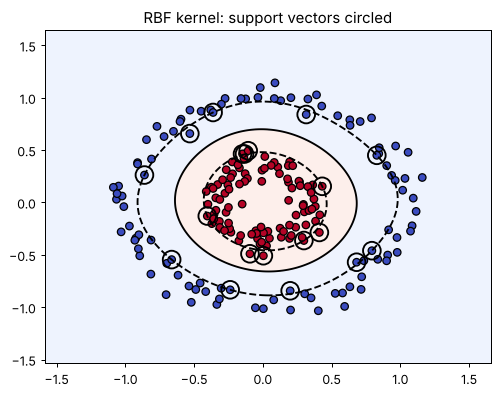

In [14]:
for kernel in ["linear", "poly", "rbf"]:
    model = SVC(kernel=kernel, degree=2, C=1.0).fit(Xc, yc)
    print(f"{kernel:6}  accuracy = {model.score(Xc, yc):.3f}  support vectors = {len(model.support_)}")

rbf = SVC(kernel="rbf", C=1.0).fit(Xc, yc)
plot_svm(rbf, Xc, yc, rbf.support_, "RBF kernel: support vectors circled")

## Summary
1. **Hyperplane** $w \cdot x + b = 0$; the sign of the score is the class, $|score| / \|w\|$ the distance
2. **Margin** $= 2 / \|w\|$; SVM keeps $\|w\|$ small to keep the margin wide
3. **Soft margin:** hinge loss lets some points violate the margin, at a cost $C$
4. **Support vectors** are the points on or inside the margin; they alone define the model
5. **Kernel trick:** a kernel gives dot products in a lifted space without building it

**Try it:** change `C` in section 5 to 0.05 and to 100 and compare the plots of the margin.